**Author: Lluis Marill**

# Card Counting in Blackjack: A Monte Carlo Study

In this notebook I use my blackjack simulator (`blackjack_sim.py`) to study whether card counting can overcome the house edge in a game with unfavourable rules, and how much risk comes with it.

**The game.** Two decks, dealer stands on soft 17, double after split allowed, no surrender, 75% penetration, and, crucially, **blackjack pays 6:5** instead of the usual 3:2. The 6:5 payout alone costs the player about 1.4% per hand, so this is a game where a basic-strategy player is expected to lose.

**The strategies.** Both players use basic strategy for every playing decision; they only differ in how much they bet:
1. **Flat betting**: always bet 1 unit.
2. **Hi-Lo counting with a steep ramp**: keep the Hi-Lo running count (+1 for 2–6, −1 for tens and aces), convert it to the true count $\mathrm{TC} = \text{running count} / \text{decks remaining}$, and bet
$$
\text{bet} = \max\big(1,\ 2(\lfloor \mathrm{TC} \rfloor - 1)\big) \text{ units}.
$$

**The experiment.** For each strategy I simulate **30 independent sessions of 10,000 rounds** and look at the bankroll paths, the expected bankroll with a confidence band, the distribution of final results, and confidence intervals for the edge.

Both strategies use the same seeds, so session $k$ of the counter sees exactly the same cards as session $k$ of the flat bettor. The only difference is the bet size, which makes the comparison paired and much sharper.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt

import blackjack_sim as bj

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Setup

In [2]:
N_ROUNDS = 10_000   # rounds per session
N_SESSIONS = 30     # independent sessions per strategy
T_CRIT = 2.045      # t-quantile, 97.5%, 29 degrees of freedom

rules = bj.Rules(decks=2, penetration=0.75, h17=False, das=True,
                 surrender=False, bj_payout=1.2)   # 6:5 blackjack

strategies = {"Flat betting": "flat", "Hi-Lo, bet 2(TC-1)": "steep"}

print("Rules:", bj.describe(rules, "flat", 8, False, False).rsplit(", flat", 1)[0])

Rules: 2 decks, S17, DAS, no surrender, BJ pays 1.2:1, 75% penetration


## 2. Running the simulations

For every session I keep the bankroll path (sampled every few rounds) together with the summary statistics returned by the simulator.

In [3]:
results = {}
for name, mode in strategies.items():
    runs = [bj.simulate(N_ROUNDS, rules, mode=mode, seed=k) for k in range(N_SESSIONS)]
    rounds = np.array([r for r, _ in runs[0]["bankroll_path"]])
    paths = np.array([[b for _, b in run["bankroll_path"]] for run in runs])
    results[name] = {"runs": runs, "rounds": rounds, "paths": paths}
    print(f"{name:20s} done, final results: mean {paths[:, -1].mean():+8.1f} units")

Flat betting         done, final results: mean   -167.1 units


Hi-Lo, bet 2(TC-1)   done, final results: mean    -23.1 units


## 3. Bankroll paths

Each thin line is one session of 10,000 rounds. The thick line is the average over the 30 sessions, and the shaded area is a pointwise 95% confidence interval for the **expected** bankroll,
$$
\bar B_t \pm t_{29,\,0.975}\, \frac{s_t}{\sqrt{30}},
$$
where $\bar B_t$ and $s_t$ are the mean and standard deviation of the 30 bankrolls after $t$ rounds.

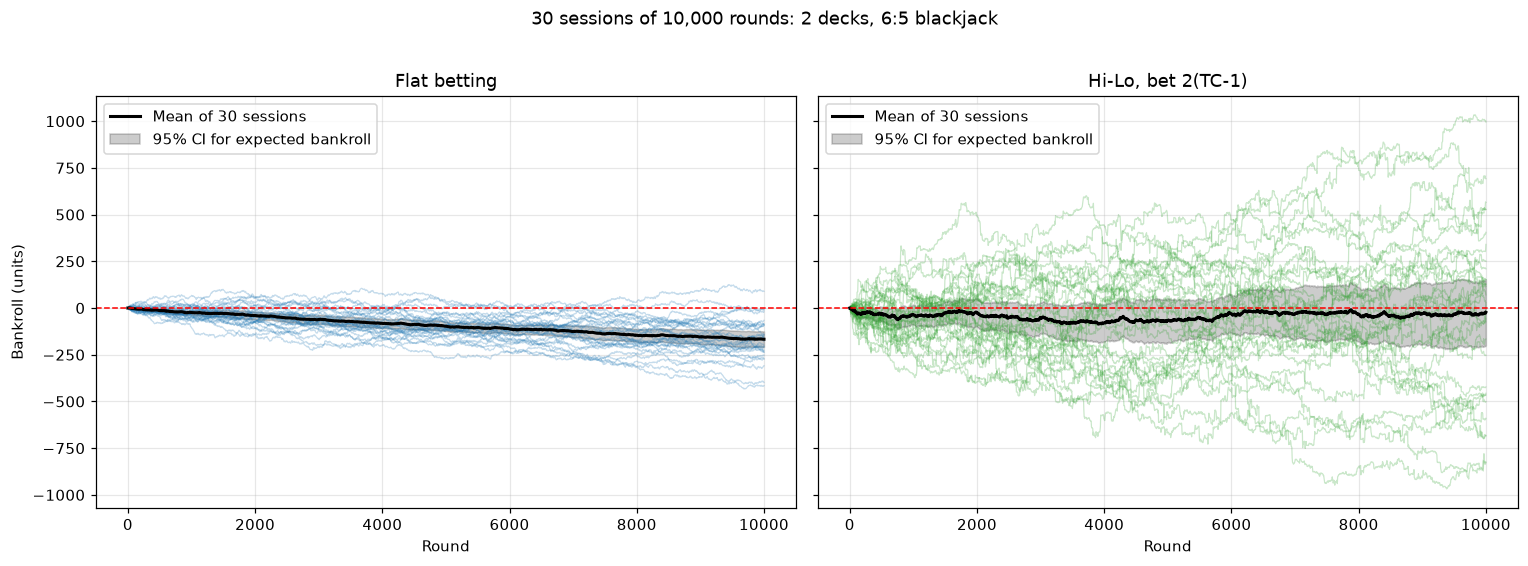

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = {"Flat betting": "tab:blue", "Hi-Lo, bet 2(TC-1)": "tab:green"}

for ax, (name, res) in zip(axes, results.items()):
    t, P = res["rounds"], res["paths"]
    mean = P.mean(axis=0)
    half = T_CRIT * P.std(axis=0, ddof=1) / sqrt(N_SESSIONS)
    for path in P:
        ax.plot(t, path, color=colors[name], alpha=0.25, lw=0.8)
    ax.plot(t, mean, color="black", lw=2, label="Mean of 30 sessions")
    ax.fill_between(t, mean - half, mean + half, color="black", alpha=0.2,
                    label="95% CI for expected bankroll")
    ax.axhline(0, color="red", ls="--", lw=1)
    ax.set_title(name)
    ax.set_xlabel("Round")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Bankroll (units)")
plt.suptitle("30 sessions of 10,000 rounds: 2 decks, 6:5 blackjack", y=1.02)
plt.tight_layout()
plt.show()

Both strategies on one plot, to compare the drift (mean) and the spread of outcomes. Here the shaded areas show the range between the 5% and 95% empirical quantiles of the 30 sessions, i.e. where a typical single session ends up, rather than the uncertainty in the mean.

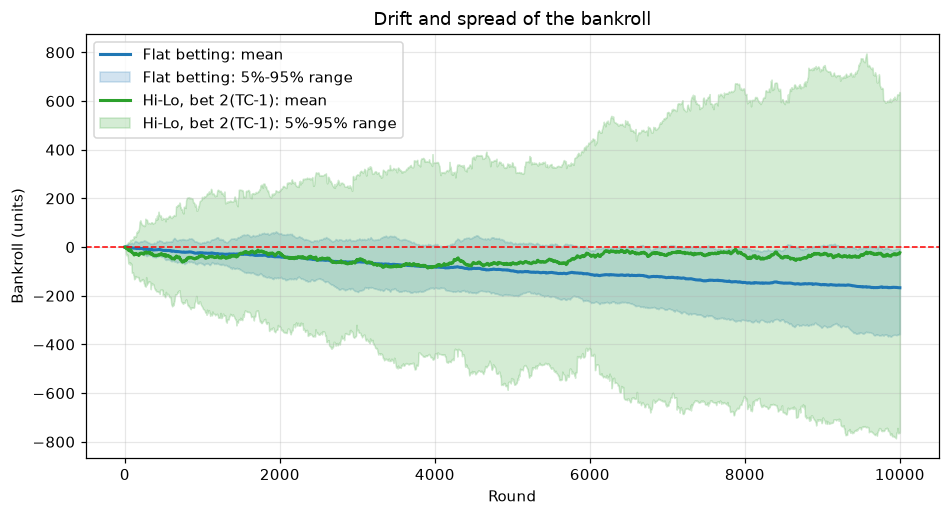

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for name, res in results.items():
    t, P = res["rounds"], res["paths"]
    lo, hi = np.quantile(P, [0.05, 0.95], axis=0)
    ax.plot(t, P.mean(axis=0), color=colors[name], lw=2, label=f"{name}: mean")
    ax.fill_between(t, lo, hi, color=colors[name], alpha=0.2, label=f"{name}: 5%-95% range")
ax.axhline(0, color="red", ls="--", lw=1)
ax.set_xlabel("Round")
ax.set_ylabel("Bankroll (units)")
ax.set_title("Drift and spread of the bankroll")
ax.legend(loc="upper left")
plt.show()

## 4. Distribution of final results

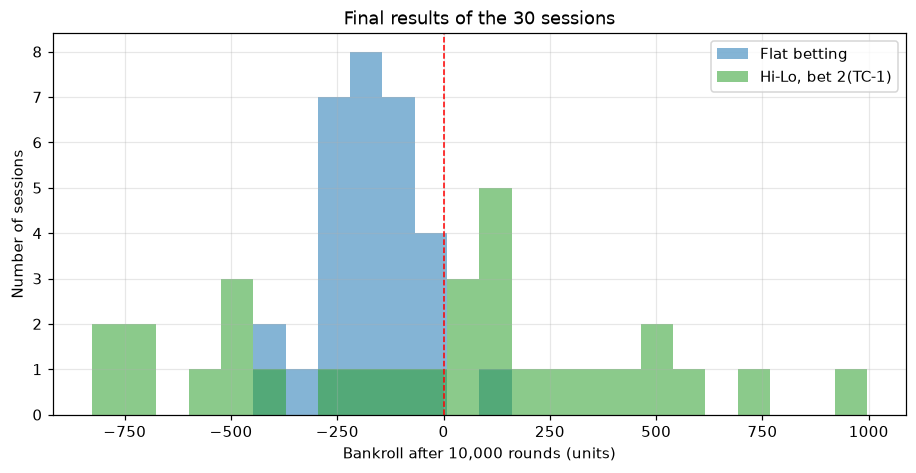

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.linspace(min(r["paths"][:, -1].min() for r in results.values()),
                   max(r["paths"][:, -1].max() for r in results.values()), 25)
for name, res in results.items():
    ax.hist(res["paths"][:, -1], bins=bins, alpha=0.55, color=colors[name], label=name)
ax.axvline(0, color="red", ls="--", lw=1)
ax.set_xlabel("Bankroll after 10,000 rounds (units)")
ax.set_ylabel("Number of sessions")
ax.set_title("Final results of the 30 sessions")
ax.legend()
plt.show()

## 5. Confidence intervals for the edge

For each session I compute the **player edge** (net result divided by the total amount initially bet) and the **EV per round** in units. The 30 sessions are independent, so a $t$-interval over sessions gives a 95% confidence interval for each quantity. I also report the average bet, the worst drawdown, and the fraction of sessions that ended in profit.

In [7]:
def ci(x):
    x = np.asarray(x)
    m, h = x.mean(), T_CRIT * x.std(ddof=1) / sqrt(len(x))
    return m, m - h, m + h

rows = {}
for name, res in results.items():
    runs = res["runs"]
    edge = [r["return_per_initial_bet"] for r in runs]
    ev = [r["mean_per_round"] for r in runs]
    m_e, lo_e, hi_e = ci(edge)
    m_v, lo_v, hi_v = ci(ev)
    rows[name] = {
        "Edge per unit bet": f"{m_e:+.2%}",
        "95% CI (edge)": f"[{lo_e:+.2%}, {hi_e:+.2%}]",
        "EV per round (units)": f"{m_v:+.4f}",
        "95% CI (EV)": f"[{lo_v:+.4f}, {hi_v:+.4f}]",
        "Average bet (units)": f"{np.mean([r['avg_bet'] for r in runs]):.2f}",
        "SD per round (units)": f"{np.mean([r['sd_per_round'] for r in runs]):.2f}",
        "Mean worst drawdown": f"{np.mean([r['worst_bankroll'] for r in runs]):+.1f}",
        "Sessions in profit": f"{np.mean([r['net'] > 0 for r in runs]):.0%}",
    }
summary = pd.DataFrame(rows)
summary

,Flat betting,"Hi-Lo, bet 2(TC-1)"
Edge per unit bet,-1.67%,-0.12%
95% CI (edge),"[-2.09%, -1.25%]","[-0.86%, +0.63%]"
EV per round (units),-0.0167,-0.0023
95% CI (EV),"[-0.0209, -0.0125]","[-0.0199, +0.0152]"
Average bet (units),1.00,2.39
SD per round (units),1.13,4.80
Mean worst drawdown,-208.4,-410.3
Sessions in profit,3%,57%


Because session $k$ of both strategies uses the same cards, I can also look at the **paired difference** in final results. This removes most of the card-luck noise that both players share.

In [8]:
diff = results["Hi-Lo, bet 2(TC-1)"]["paths"][:, -1] - results["Flat betting"]["paths"][:, -1]
m, lo, hi = ci(diff)
print(f"Counter minus flat bettor after {N_ROUNDS:,} rounds: {m:+.1f} units "
      f"(95% CI {lo:+.1f} to {hi:+.1f})")
print(f"Counter did better in {np.mean(diff > 0):.0%} of the sessions")

Counter minus flat bettor after 10,000 rounds: +144.0 units (95% CI -10.0 to +297.9)
Counter did better in 63% of the sessions


## 6. Where does the counter's edge come from?

The counter's advantage comes from betting more when the remaining cards are rich in tens and aces. The plot below shows how often each true count occurs in a shoe and what the counter bets there.

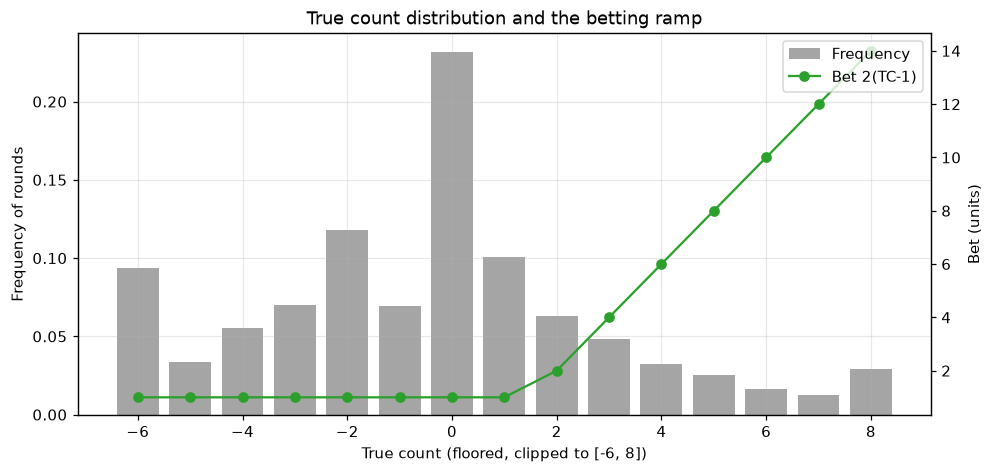

Rounds at TC >= 2 (where the counter raises the bet): 22.7%


In [9]:
import random
rng = random.Random(0)
shoe = bj.Shoe(rules, rng)
tcs = []
for _ in range(200_000):
    if shoe.needs_shuffle():
        shoe.shuffle()
    tcs.append(int(np.floor(shoe.true_count())))
    bj.play_round(shoe, rules, 1.0)
tcs = np.clip(tcs, -6, 8)

values, counts = np.unique(tcs, return_counts=True)
fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(values, counts / counts.sum(), color="tab:gray", alpha=0.7, label="Frequency")
ax1.set_xlabel("True count (floored, clipped to [-6, 8])")
ax1.set_ylabel("Frequency of rounds")
ax2 = ax1.twinx()
ax2.plot(values, [bj.bet_size("steep", v, 8) for v in values], "o-", color="tab:green",
         label="Bet 2(TC-1)")
ax2.set_ylabel("Bet (units)")
ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
ax1.set_title("True count distribution and the betting ramp")
plt.show()

print(f"Rounds at TC >= 2 (where the counter raises the bet): {np.mean(tcs >= 2):.1%}")

## 7. Conclusions

- **Flat betting clearly loses.** With 6:5 blackjack, the basic-strategy player has an edge of about −1.7% per unit bet, with a 95% confidence interval of roughly [−2.1%, −1.3%], entirely below zero. Only 1 of the 30 sessions ended in profit.
- **Counting with a steep ramp removes almost all of the house edge, but not more.** Betting $2(\mathrm{TC}-1)$ units brings the edge to about −0.1%, i.e. essentially break-even. The confidence interval, roughly [−0.9%, +0.6%], contains zero, so with this amount of data we cannot say whether the counter has a positive or a negative edge. The 6:5 payout is costly enough that a pure betting ramp barely compensates for it.
- **On the same cards, the counter does better.** The paired comparison shows the counter ending about 144 units ahead of the flat bettor on average (the 95% interval, roughly [−10, +298], only just includes zero), and beating the flat bettor in about 63% of the sessions.
- **The price is variance.** The counter's average bet is about 2.4 units, and the standard deviation per round is more than four times that of the flat bettor. The average worst drawdown roughly doubles, and individual sessions end far in the red or far in the black. This is why the confidence intervals for the counter are so much wider.

**Caveats and extensions.** The simulation assumes perfect counting and perfect basic strategy, an unlimited bankroll, and no table maximum. In a real casino a spread this steep would quickly attract attention. Natural extensions, all supported by the simulator, are true-count playing deviations (`deviations=True`), wonging (sitting out at negative counts), comparing with a 3:2 game, and running more sessions to tighten the confidence intervals.